# W06. Analiza zachowania człowieka

**Wersja źródła:** 1.1.4 · **Data:** 2026-11-04


## W06. Slajd 25

In [ ]:
import numpy as np

t = np.linspace(0.0, 1.0, 101)
bezposrednia = np.column_stack((t, t))
zakrzywiona = np.column_stack((t + 0.22 * np.sin(np.pi * t), t))


## W06. Slajd 26

In [ ]:
def metryki(traj):
    segmenty = np.diff(traj, axis=0)
    droga = np.linalg.norm(segmenty, axis=1).sum()
    b = traj[-1] - traj[0]
    if np.linalg.norm(b) == 0:
        raise ValueError("Początek i cel nie mogą się pokrywać")
    d = traj - traj[0]
    odchylenie = (b[0] * d[:, 1] - b[1] * d[:, 0]) / np.linalg.norm(b)
    return droga, np.max(np.abs(odchylenie))

for nazwa, xy in [("prosta", bezposrednia), ("krzywa", zakrzywiona)]:
    print(nazwa, np.round(metryki(xy), 3))

# Wrażliwość długości i MD na gęstość próbkowania
for punkty in (21, 101):
    u = np.linspace(0.0, 1.0, punkty)
    xy = np.column_stack((u + .22*np.sin(np.pi*u), u))
    print(punkty, "punktów:", np.round(metryki(xy), 3))


prosta [1.414 0.   ]
krzywa [1.459 0.156]
21 punktów: [1.459 0.156]
101 punktów: [1.459 0.156]


## W06. Slajd 27

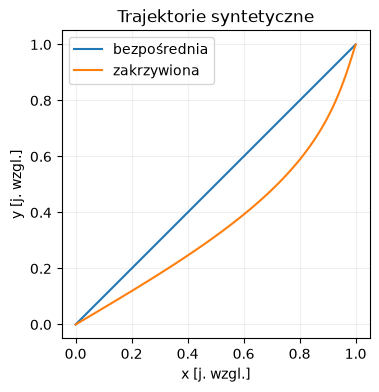

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(bezposrednia[:, 0], bezposrednia[:, 1], label="bezpośrednia")
ax.plot(zakrzywiona[:, 0], zakrzywiona[:, 1], label="zakrzywiona")
ax.set(xlabel="x [j. wzgl.]", ylabel="y [j. wzgl.]",
       title="Trajektorie syntetyczne")
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.2)
ax.legend()
plt.show()


## W06. Slajd 28

In [ ]:
from collections import Counter

sesja = ["start", "wybor", "rewizja", "wybor", "zatwierdzenie"]
liczniki = Counter(zip(sesja[:-1], sesja[1:]))
wyjscia = Counter(a for a, b in zip(sesja[:-1], sesja[1:]))

for (a, b), n in sorted(liczniki.items()):
    print(f"{a} → {b}: P={n / wyjscia[a]:.2f}")


rewizja → wybor: P=1.00
start → wybor: P=1.00
wybor → rewizja: P=0.50
wybor → zatwierdzenie: P=0.50
